# Step 1 Data Preparation

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

RANDOM_STATE = 42

# Load dataset
df = pd.read_csv("bank-additional-full.csv", sep=";")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


## Explore

In [19]:
# Dataset dimensions
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Data types
print("\nData types:")
print(df.dtypes.value_counts())

# Column information
print("\nColumn information:")
df.info()

# Missing values
print("\nMissing values:")
print(df.isnull().sum())

# Target distribution
print("\nTarget distribution:")
print(df["y"].value_counts())

print("\nTarget proportions:")
print(df["y"].value_counts(normalize=True))

# Positive-class proportion
positive_proportion = (df["y"] == "yes").mean()
print(f"\nPositive-class proportion: {positive_proportion:.4%}")

Number of rows: 41188
Number of columns: 21

Data types:
object     11
float64     6
int64       4
Name: count, dtype: int64

Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   age                   41188 non-null  int64  
 1   job                   41188 non-null  object 
 2   marital               41188 non-null  object 
 3   education             41188 non-null  object 
 4   default               41188 non-null  object 
 5   housing               41188 non-null  object 
 6   loan                  41188 non-null  object 
 7   contact               41188 non-null  object 
 8   month                 41188 non-null  object 
 9   day_of_week           41188 non-null  object 
 10  campaign              41188 non-null  int64  
 11  pdays                 1515 non-null   float64
 12  previous              4118

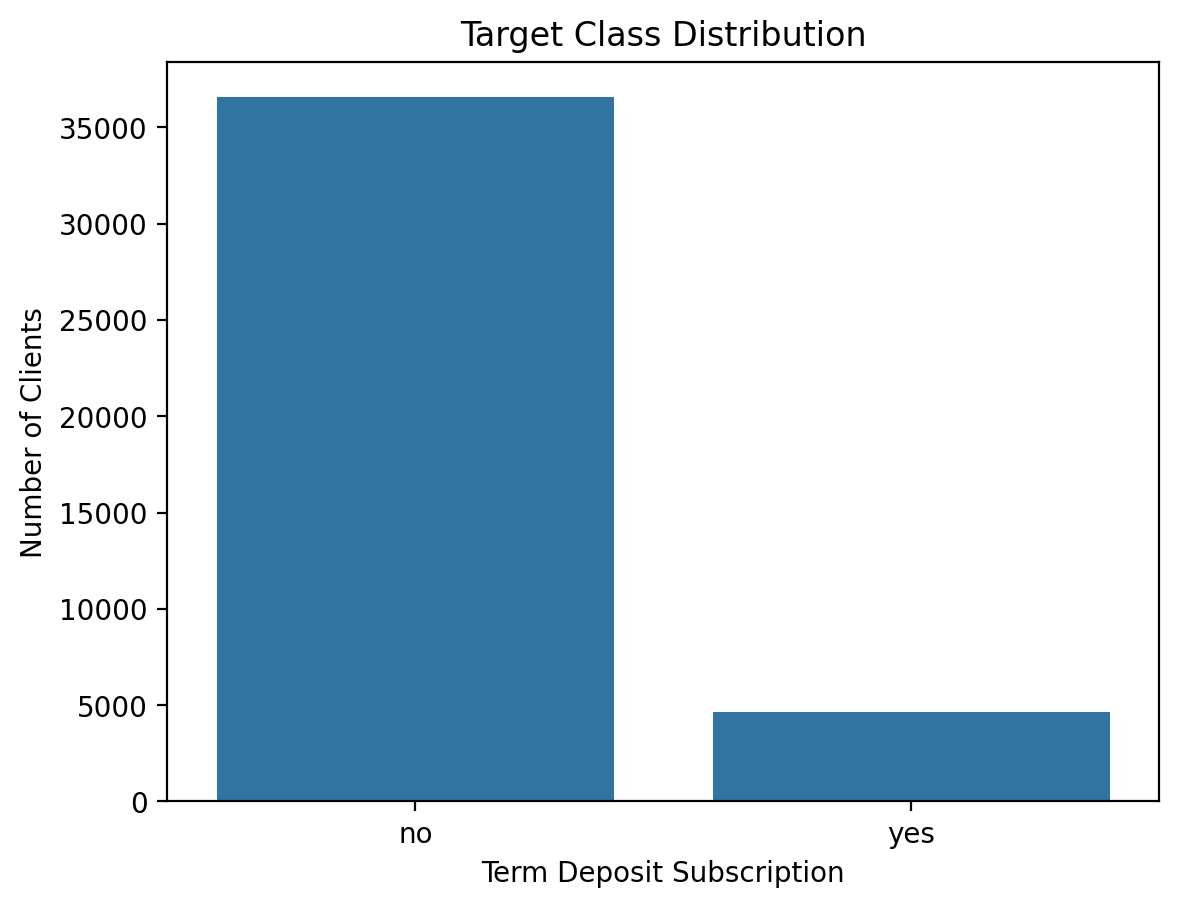

In [12]:
sns.countplot(data=df, x="y")

plt.title("Target Class Distribution")
plt.xlabel("Term Deposit Subscription")
plt.ylabel("Number of Clients")
plt.show()

## Unknown categorical values

In [13]:
categorical_cols = df.select_dtypes(include="object").columns.drop("y")

print("Unknown categorical values:\n")

for col in categorical_cols:
    count = (df[col] == "unknown").sum()
    if count > 0:
        print(f"{col}: {count} ({count / len(df):.2%})")

Unknown categorical values:

job: 330 (0.80%)
marital: 80 (0.19%)
education: 1731 (4.20%)
default: 8597 (20.87%)
housing: 990 (2.40%)
loan: 990 (2.40%)


In [14]:
print("Number of pdays = 999:", (df["pdays"] == 999).sum())
print(
    "Percentage of pdays = 999:",
    f"{(df['pdays'] == 999).mean():.2%}"
)

Number of pdays = 999: 39673
Percentage of pdays = 999: 96.32%


## Clean the dataset

In [15]:
# Create indicator for whether the client was previously contacted
df["previously_contacted"] = (df["pdays"] != 999).astype(int)

# Replace special value 999 with NaN
df["pdays"] = df["pdays"].replace(999, np.nan)

# Remove duration 
df = df.drop(columns=["duration"])

# Separate predictors and target
X = df.drop(columns=["y"])
y = (df["y"] == "yes").astype(int)

print("Predictor shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts(normalize=True))

Predictor shape: (41188, 20)
Target shape: (41188,)

Target distribution:
y
0    0.887346
1    0.112654
Name: proportion, dtype: float64


## Create train/validation/test splits

In [16]:
# First split: 70% training, 30% remaining
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y
)

# Second split: 15% validation, 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=y_temp
)

# Display split sizes
print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)

Training set: (28831, 20)
Validation set: (6178, 20)
Test set: (6179, 20)


## Check class proportion

In [17]:
split_summary = pd.DataFrame({
    "Dataset": ["Overall", "Training", "Validation", "Test"],
    "Rows": [len(y), len(y_train), len(y_val), len(y_test)],
    "Positive Class Proportion": [
        y.mean(),
        y_train.mean(),
        y_val.mean(),
        y_test.mean()
    ]
})

split_summary["Positive Class Proportion"] = (
    split_summary["Positive Class Proportion"].map(lambda x: f"{x:.4%}")
)

display(split_summary)

,Dataset,Rows,Positive Class Proportion
0,Overall,41188,11.2654%
1,Training,28831,11.2657%
2,Validation,6178,11.2658%
3,Test,6179,11.2640%


## Preprocessing

In [20]:
# Identify numerical and categorical features
numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical features:", len(numeric_features))
print(numeric_features)

print("\nCategorical features:", len(categorical_features))
print(categorical_features)

Numerical features: 10
['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'previously_contacted']

Categorical features: 10
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']


In [ ]:
# Numerical preprocessing for GBDT
numeric_tree = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Numerical preprocessing for MLP
numeric_mlp = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# GBDT preprocessing
preprocessor_gbdt = ColumnTransformer([
    ("num", numeric_tree, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

# MLP preprocessing
preprocessor_mlp = ColumnTransformer([
    ("num", numeric_mlp, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

In [ ]:
# GBDT preprocessing
X_train_gbdt = preprocessor_gbdt.fit_transform(X_train)
X_val_gbdt = preprocessor_gbdt.transform(X_val)
X_test_gbdt = preprocessor_gbdt.transform(X_test)

# MLP preprocessing
X_train_mlp = preprocessor_mlp.fit_transform(X_train)
X_val_mlp = preprocessor_mlp.transform(X_val)
X_test_mlp = preprocessor_mlp.transform(X_test)

print("GBDT transformed shapes:")
print("Training:", X_train_gbdt.shape)
print("Validation:", X_val_gbdt.shape)
print("Test:", X_test_gbdt.shape)

print("\nMLP transformed shapes:")
print("Training:", X_train_mlp.shape)
print("Validation:", X_val_mlp.shape)
print("Test:", X_test_mlp.shape)

GBDT transformed shapes:
Training: (28831, 63)
Validation: (6178, 63)
Test: (6179, 63)

MLP transformed shapes:
Training: (28831, 63)
Validation: (6178, 63)
Test: (6179, 63)
